# P15 — Composição celular por biblioteca (CLR + lm, forest plots)

**Pergunta.** A proporção de cada tipo de célula T CD4⁺ da anotação do projeto (P09) muda com o
estímulo por *M. leprae* (NS × ML) e entre os grupos clínicos (controle, PB, MB, NP)?

**Rótulos.** `anotacao` (10 rótulos CD4⁺, granularidade fina) e `grupo` (5 categorias, a
granularidade larga, no papel do `Celltypes`/`BroadCelltypes` do script B), sem contaminante
nem baixa qualidade. A versão com o atlas L2/L1 está em `P15_composicao_atlasL2` (saídas em
`P15_composicao/`).

**Ponto de partida.** O objeto final do P13 (`dataReseq/analises_previas/P13_objeto_final/reseq_final.h5ad`).

**Método: o mesmo do projeto espacial**, de três referências:

| | referência | o que vem dela |
| --- | --- | --- |
| A | `spatialPaper/src/integration/composition_condition_by_resolution.R` | painéis A–E: composição com dendrograma (pvclust), média por grupo, forests C/D/E |
| B | `spatialPaper/src/integration/composition_classificacao_forest.R` | forests de classificação par a par e do estímulo dentro de cada grupo; granularidade larga + fina |
| C | `spatialPaper/src/forest_composicao/` | forest único com os dados brutos ao lado; pseudocontagem na escala de contagem; filtro de prevalência; covariáveis no `lm` |

O cálculo comum às três: proporção de cada tipo **por biblioteca** (mínimo de
30 células) → CLR → `lm(CLR ~ grupo)` por tipo → BH entre os tipos. A e B
rodam no R, com o código copiado ([functions/composicao_forest.R](../../functions/composicao_forest.R));
C roda em Python, com os módulos copiados ([functions/composicao.py](../../functions/composicao.py),
[functions/forest_composicao.py](../../functions/forest_composicao.py)).

## Adaptação: o que mudou e por quê

**Obrigatório, porque os dados são outros:**

1. **Entrada.** O R lê um `obs.csv` escrito aqui, não o objeto Seurat.
2. **Células.** Só as CD4⁺: `grupo` fora de contaminante e baixa qualidade, 30.933 de 35.247.
3. **Colunas.** Amostra = `library_id` (14 bibliotecas, 7 pacientes). Tipo celular =
   `anotacao` (10 rótulos) e `grupo` (5 categorias), as duas granularidades de B.
   Condição de A = estímulo (referência: não estimulado). Resposta de A e classificação de B =
   `classificacao` com HNP44 = NP (no objeto o HNP44 vem como MB; B aplica a mesma regra, `^HNP` → NP).
4. **Painéis C e D.** Em A são FB × UB, um contraste binário, dentro de cada condição. Aqui a
   classificação tem 4 níveis e MB e NP têm uma biblioteca por estímulo; C e D ficam
   PB × controle dentro de NS e dentro de ML (2 × 3 bibliotecas), o único contraste binário com
   mais de uma biblioteca por lado.
5. **Pareamento.** As 14 bibliotecas são 7 pares NS/ML do mesmo paciente. O painel E é feito como
   em A (sem o paciente) e repetido como **E2, com o paciente no `lm`** (`CLR ~ estímulo + paciente`,
   6 graus de liberdade no resíduo). O modelo com covariáveis é o de C; nenhum dos três scripts
   tinha pares.
6. **Cores do estímulo.** As do resto do Reseq (azul NS, laranja ML); as de B usavam para o ML o
   mesmo vermelho do MB.
7. **Forest com IC indefinido.** Com uma biblioteca por lado (estímulo dentro do MB e do NP) o `lm`
   fica sem resíduo; o eixo do forest de A/B quebrava. Agora usa a faixa das estimativas.

**Cosmético:** tipos na ordem naive → memória → ativada → citotóxica → Treg (não alfabética), nome da biblioteca no eixo x do
painel A (são 14, não 28), rótulos em português e vírgula decimal.

**Mantido como nas referências:** pseudocontagem 1e-6 na proporção (A e B), ≥ 30 células por
amostra, teste só de tipos com variância > 0, `emmeans::pairs(adjust = "none")`, BH dentro de cada
comparação, pvclust (CLR, correlação, Ward.D2, 1.000 réplicas, AU ≥ 95 %), formas de
significância (✱ FDR < 0,05; ◆ p < 0,05). A pseudocontagem de contagem e o filtro de prevalência
de C entram como sensibilidade, lado a lado.

**Herdado das referências, sem correção:** os forests de classificação de B usam as 14
bibliotecas juntas (cada paciente conta duas vezes, NS e ML), e MB e NP são um paciente cada.
Esses contrastes são descritivos: com 7 pacientes, só o estímulo pareado e PB × controle
admitem inferência.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import warnings
warnings.filterwarnings("ignore")

import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from functions import config, io, issues, plotting
from functions import composicao as CP
from functions import forest_composicao as FR
from functions.droplets import run_r

NB = "analises_previas/P15_composicao_anotacao"
FINA, LARGA = "anotacao", "grupo"
GRANS = [FINA, LARGA]
FIG = config.FIGURES / NB
TAB = config.TABLES / NB
WORK = config.HEAVY_OUT / NB
log = issues.IssueLog(NB)
pd.set_option("display.width", 220)

## 1. Células e desenho

In [2]:
a = ad.read_h5ad(config.DATA_OUT / "analises_previas/P13_objeto_final" / "reseq_final.h5ad", backed="r")
o = a.obs
cd4 = ~o["grupo"].isin(["contaminante", "baixa qualidade"])
cel = o.loc[cd4, ["library_id", "patient", "estimulo", FINA, LARGA]].copy()
for c in cel.columns:
    cel[c] = cel[c].astype(str)
# classificação com HNP44 = NP (regra do script B: library_id começando com HNP)
cel["classificacao"] = cel["patient"].map(config.PATIENT_CLASSIFICATION)
assert cel["classificacao"].notna().all()
NIVEIS = {
    FINA: ["CD4 naive", "CD4 transição naive/Tcm", "CD4 Tcm", "CD4 Tcm/Tfh", "CD4 Tem GZMK⁺", "CD4 Th17",
           "CD4 ativada", "CD4 ativada (Th17)", "CD4 citotóxica (Temra)", "Treg"],
    LARGA: ["CD4 naive", "CD4 memória", "CD4 ativada", "CD4 citotóxica", "Treg"],
}
for g, nv in NIVEIS.items():
    assert set(cel[g]) == set(nv), (g, set(cel[g]) ^ set(nv))
print(f"{len(o):,} células no objeto · {len(cel):,} CD4⁺".replace(",", "."))
display(pd.crosstab(cel[FINA], cel[LARGA]).reindex(NIVEIS[FINA])[NIVEIS[LARGA]])

desenho = (cel.groupby("library_id")
              .agg(paciente=("patient", "first"), classificacao=("classificacao", "first"),
                   estimulo=("estimulo", "first"), celulas=("patient", "size"))
              .sort_values(["classificacao", "paciente", "estimulo"]))
display(desenho)
print(pd.crosstab(desenho["classificacao"], desenho["estimulo"]))

WORK.mkdir(parents=True, exist_ok=True)
io._assert_writable(WORK / "obs.csv")
cel.reset_index(names="cell").to_csv(WORK / "obs.csv", index=False)
_ = (WORK / "niveis.tsv").write_text("".join("\t".join([g] + nv) + "\n" for g, nv in NIVEIS.items()))

35.247 células no objeto · 30.933 CD4⁺


grupo,CD4 naive,CD4 memória,CD4 ativada,CD4 citotóxica,Treg
anotacao,,,,,
CD4 naive,11759,0,0,0,0
CD4 transição naive/Tcm,0,2696,0,0,0
CD4 Tcm,0,4968,0,0,0
CD4 Tcm/Tfh,0,3086,0,0,0
CD4 Tem GZMK⁺,0,56,0,0,0
CD4 Th17,0,2159,0,0,0
CD4 ativada,0,0,2798,0,0
CD4 ativada (Th17),0,0,357,0,0
CD4 citotóxica (Temra),0,0,0,1321,0


,paciente,classificacao,estimulo,celulas
library_id,,,,
MB34_ML,MB34,MB,estimulado,913
MB34_NS,MB34,MB,nao estimulado,1922
HNP44_ML,HNP44,NP,estimulado,1846
HNP44_NS,HNP44,NP,nao estimulado,95
PB20_ML,PB20,PB,estimulado,740
PB20_NS,PB20,PB,nao estimulado,558
PB21_ML,PB21,PB,estimulado,9281
PB21_NS,PB21,PB,nao estimulado,3485
CTH92_ML,CTH92,controle,estimulado,1231


estimulo       estimulado  nao estimulado
classificacao                            
MB                      1               1
NP                      1               1
PB                      2               2
controle                3               3


## 2. Referências A e B, no R

Roda as duas granularidades (`anotacao` e `grupo`). Saem, por granularidade:
`Figure_ABCDE` (A, com o E2 pareado ao lado do E), os painéis soltos, `Figure_forests_classificacao`
(B) e as tabelas `Comparisons_*`, `SampleClusters_*` e `sensibilidade_pseudocontagem_*`.

In [3]:
r = run_r("composicao_forest.R", [WORK, FIG, TAB], timeout=3600)
(WORK / "log_R.txt").write_text(r.stdout + "\n" + r.stderr)
print("\n".join(l for l in r.stderr.splitlines() if l.startswith((">>>", "Removendo", "Clusteriza"))))
for p in sorted(FIG.glob("*.png")):
    io.register(stage=NB, name=p.stem, kind="figure", path=p, description="saída de composicao_forest.R")
for p in sorted(TAB.glob("*.csv")):
    io.register(stage=NB, name=p.stem, kind="table", path=p, description="saída de composicao_forest.R")

Clusterização hierárquica: 14 amostras x 10 tipos | dist = correlation | linkage = ward.D2 | CLR = TRUE | nboot = 1000
>>> Clusters de amostras com AU >= 95%: 4
>>> anotacao | C: nenhum tipo com p < 0,05
>>> anotacao | D: nenhum tipo com p < 0,05
>>> anotacao | E: CD4 Th17 (p=0,0012, FDR=0,012); CD4 Tcm (p=0,0073, FDR=0,037); CD4 ativada (Th17) (p=0,038, FDR=0,13)
>>> anotacao | E2: CD4 Th17 (p=0,0061, FDR=0,061); CD4 Tcm (p=0,034, FDR=0,17)
Clusterização hierárquica: 14 amostras x 5 tipos | dist = correlation | linkage = ward.D2 | CLR = TRUE | nboot = 1000
>>> Clusters de amostras com AU >= 95%: 3
>>> grupo | C: nenhum tipo com p < 0,05
>>> grupo | D: nenhum tipo com p < 0,05
>>> grupo | E: CD4 memória (p=0,031, FDR=0,082); CD4 ativada (p=0,033, FDR=0,082)
>>> grupo | E2: CD4 ativada (p=0,0022, FDR=0,011); CD4 memória (p=0,024, FDR=0,046); CD4 naive (p=0,028, FDR=0,046)


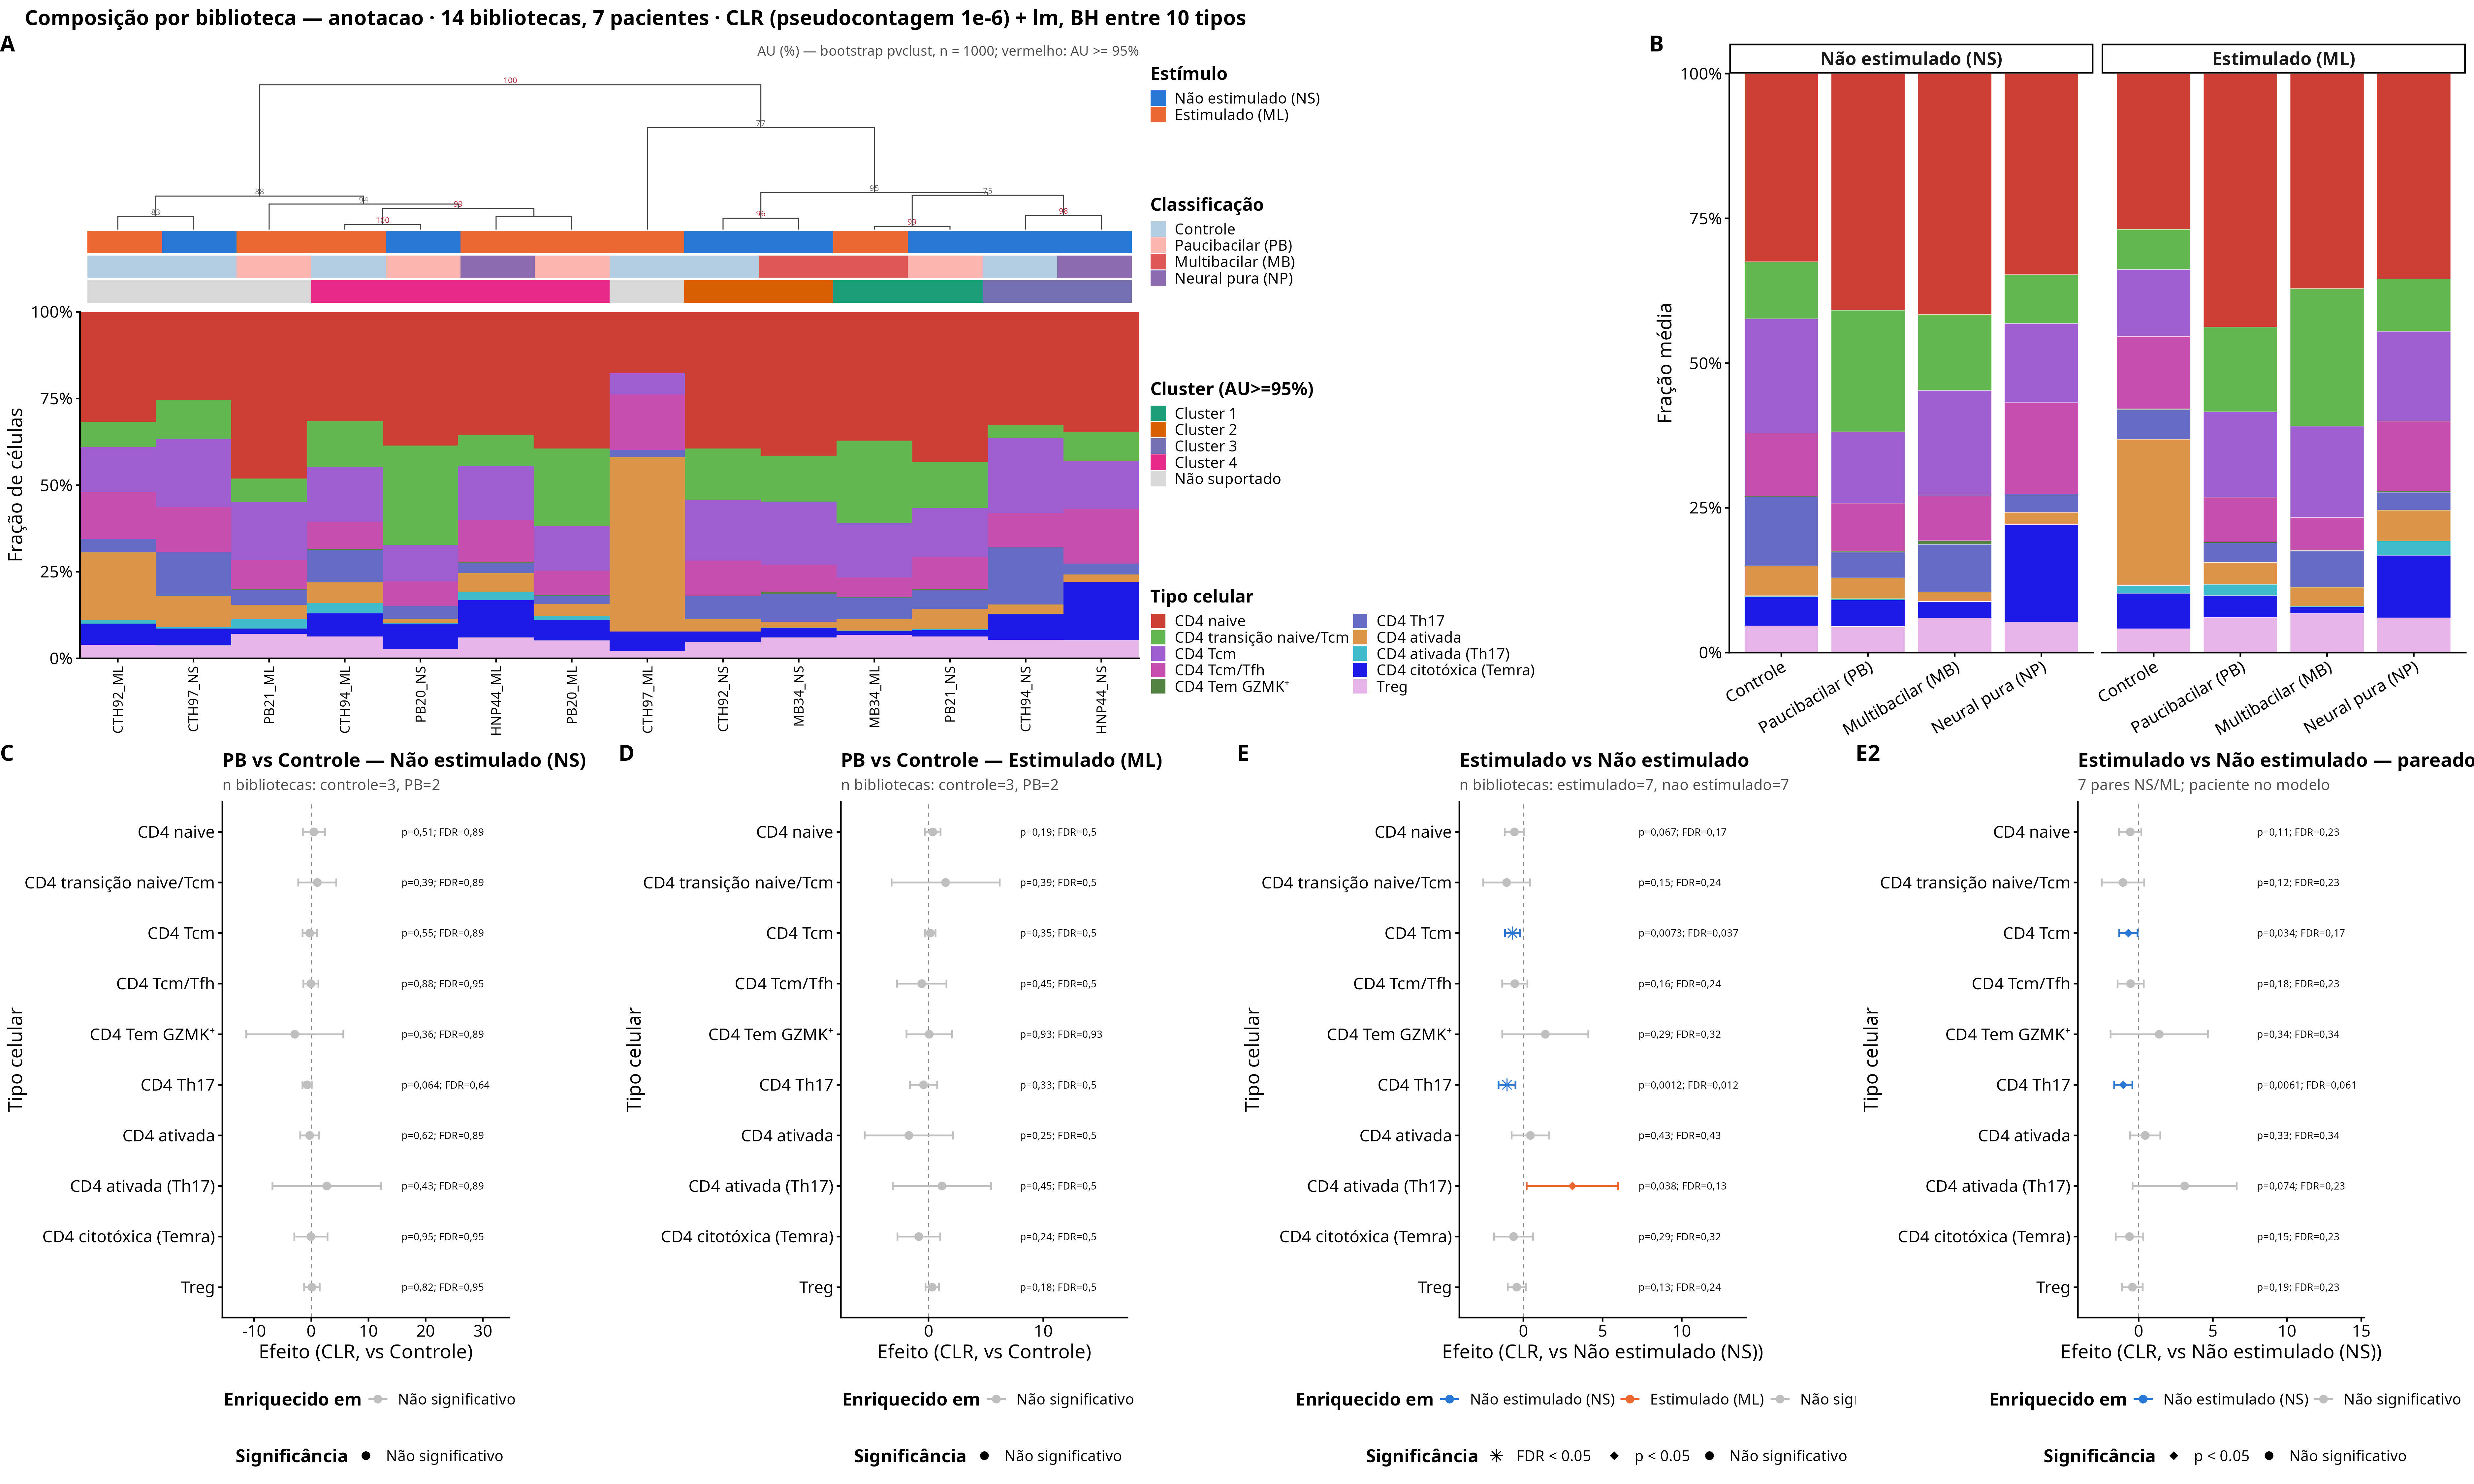

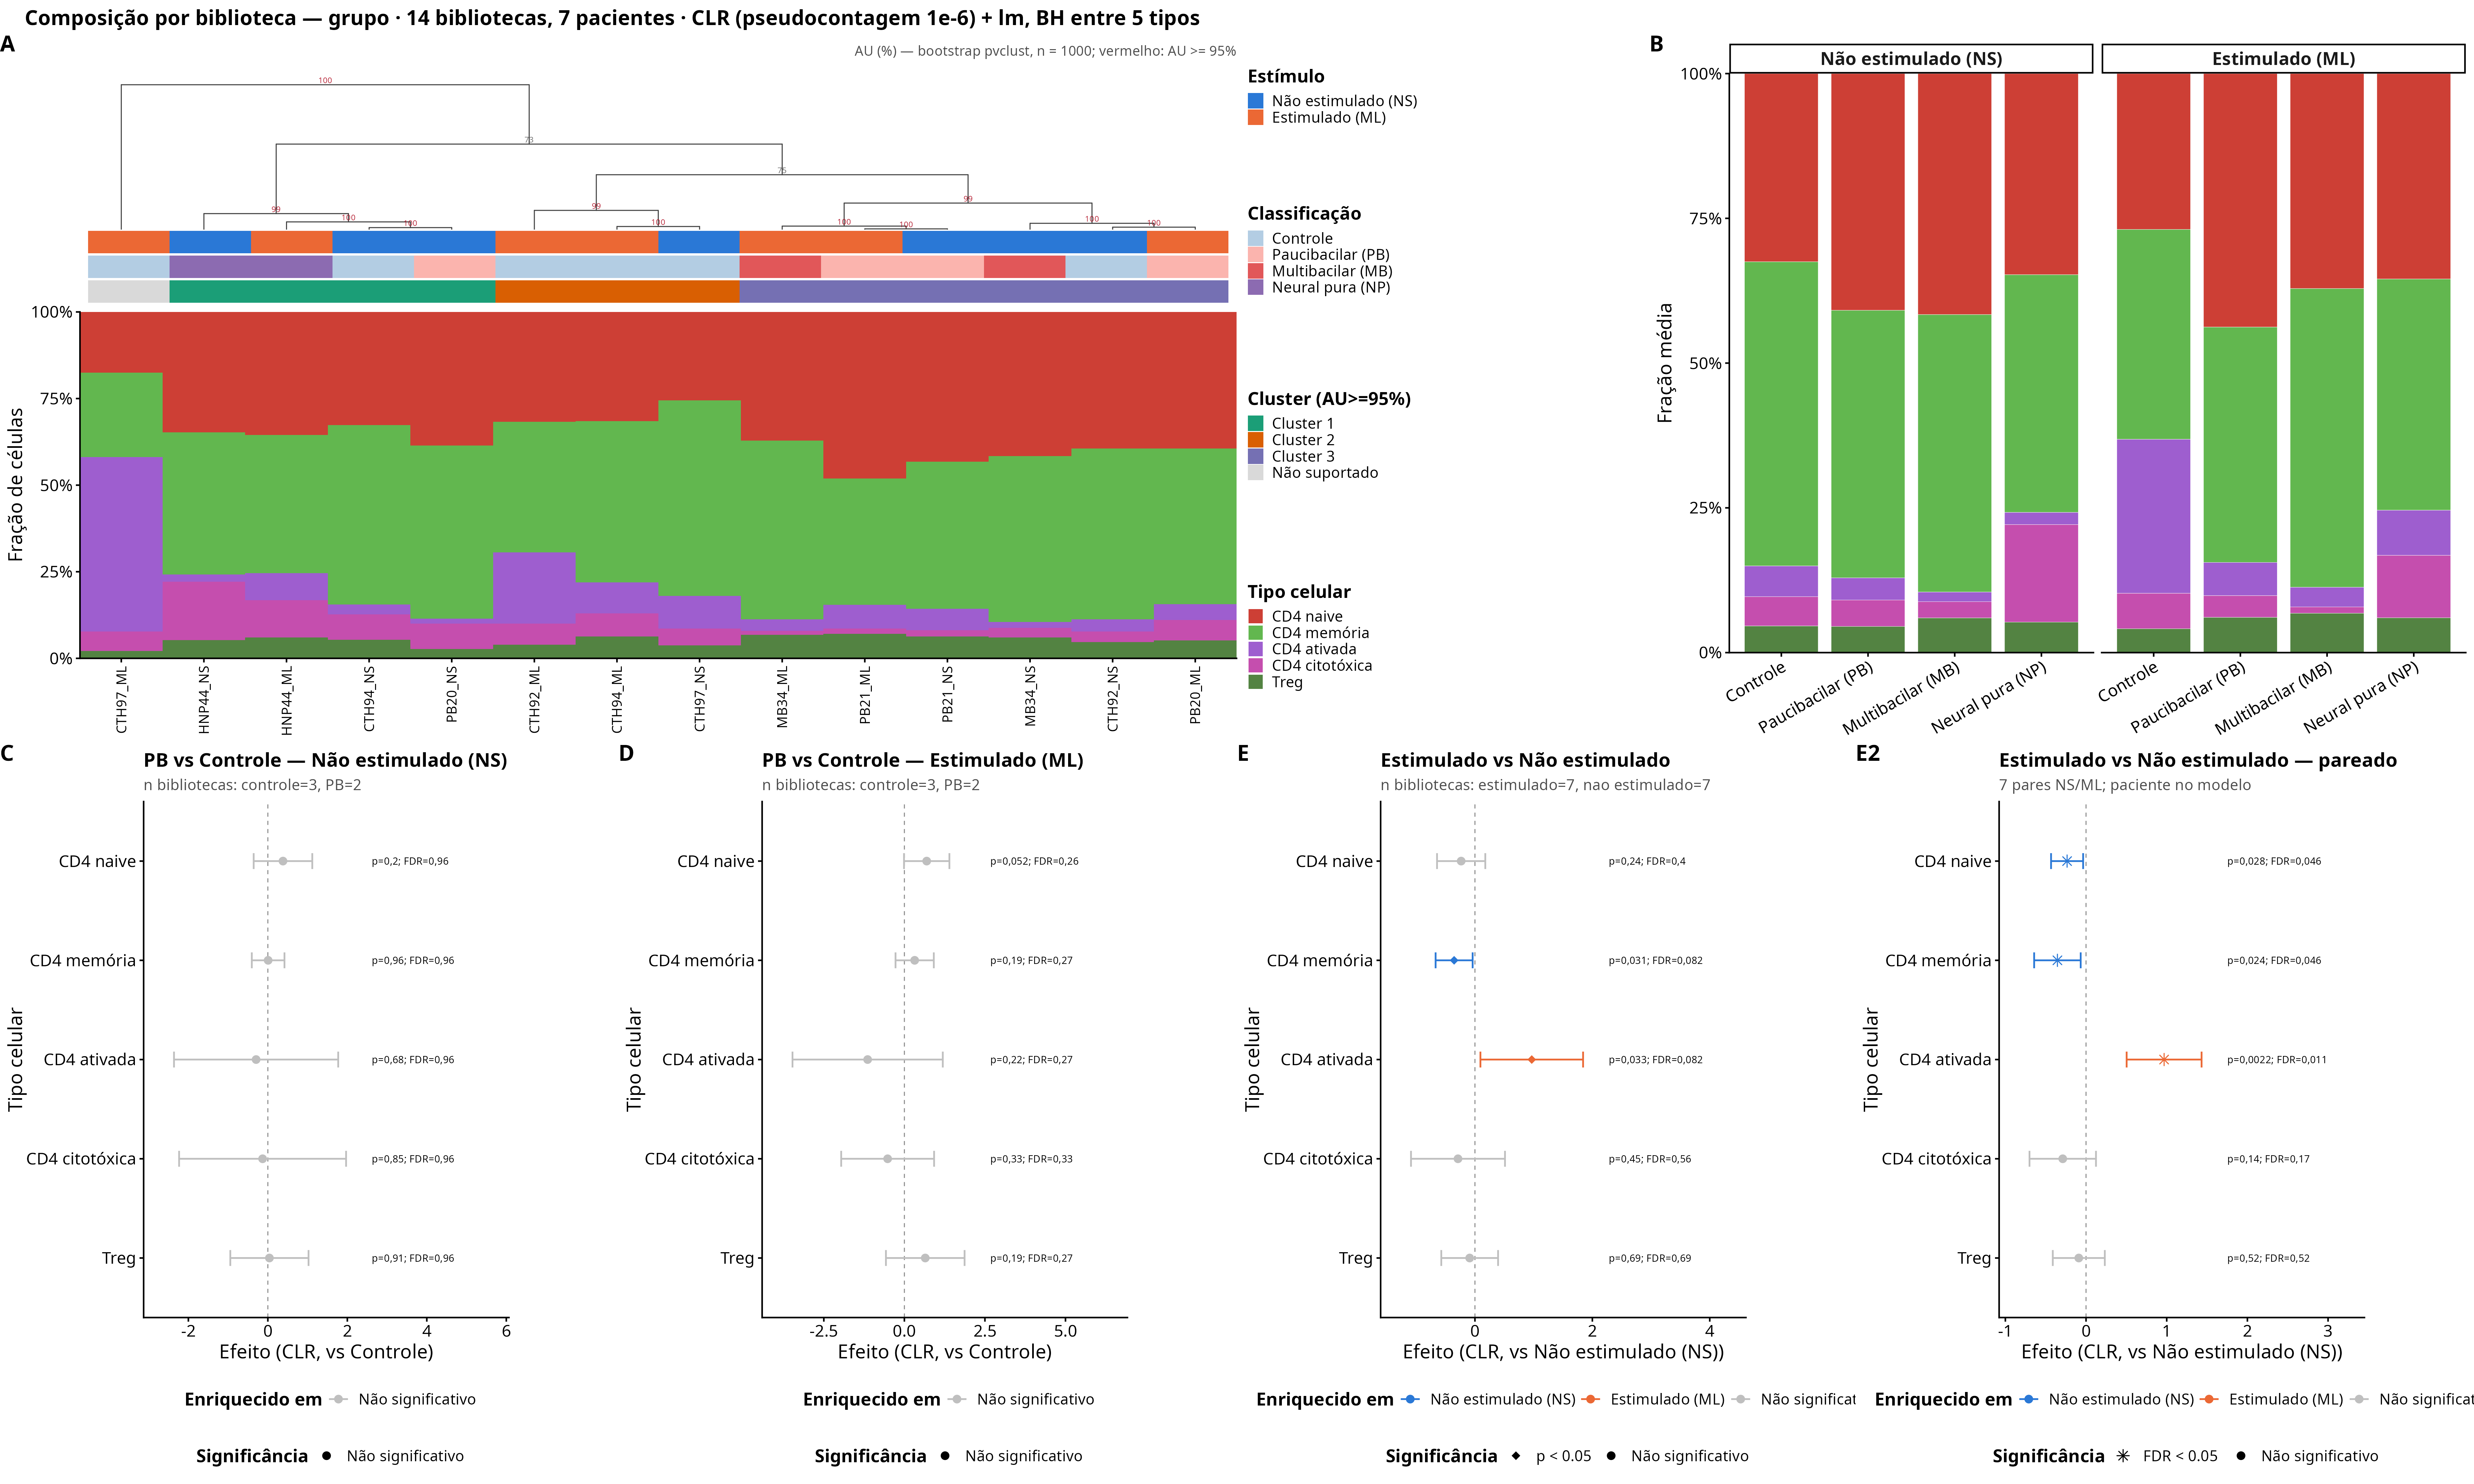

In [4]:
display(Image(filename=str(FIG / f"Figure_ABCDE_{FINA}.png"), width=1400))
display(Image(filename=str(FIG / f"Figure_ABCDE_{LARGA}.png"), width=1400))

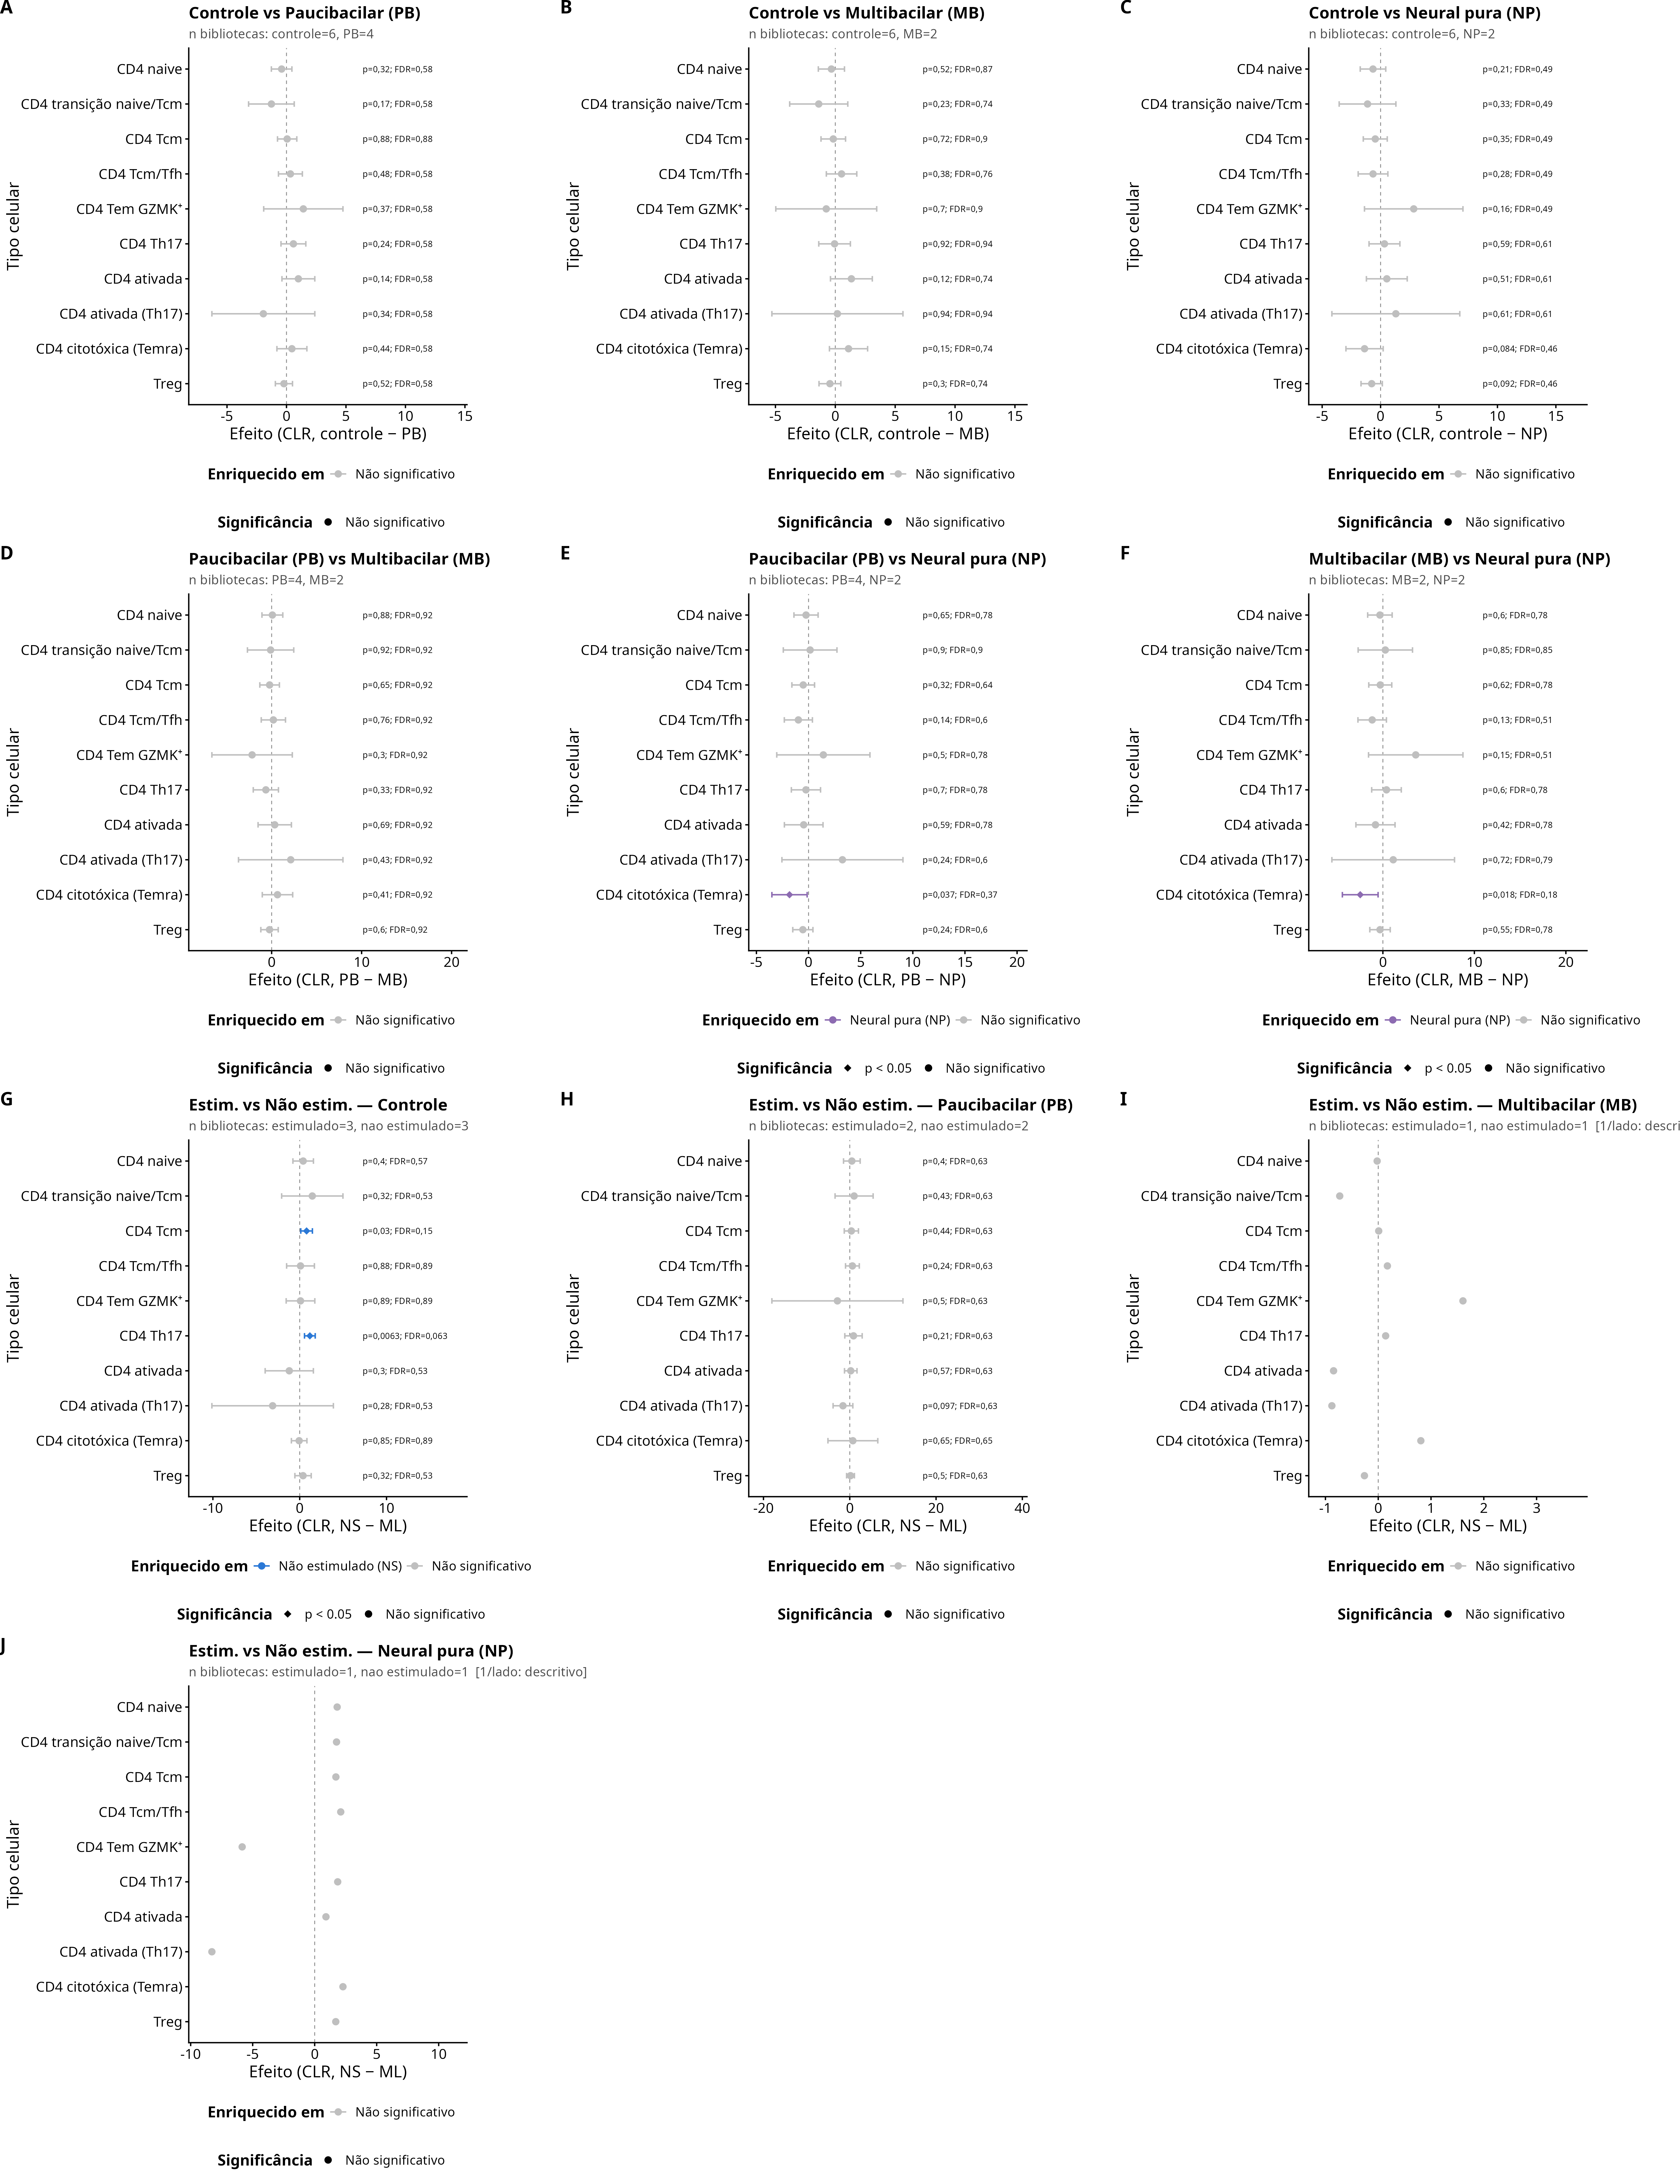

In [5]:
display(Image(filename=str(FIG / f"Figure_forests_classificacao_{FINA}.png"), width=1300))

## 3. Referência C: o contraste pareado NS × ML num forest único

O mesmo E2 (`CLR ~ estímulo + paciente`), com as duas escolhas de C: pseudocontagem na escala de
contagem, `(k + 0,5) / (N + 0,5 K)`, e filtro de prevalência (tipo presente em ≥ 1 % das células
de ≥ 3 bibliotecas de cada estímulo). Os quatro modelos são sempre calculados, como em
`run_analise.py`; a figura usa o de C (contagem + prevalência + paciente).

In [6]:
ORDEM = ["estimulado", "nao estimulado"]            # contraste ML − NS: efeito > 0 = maior em ML
CORES = {"nao estimulado": plotting.STIMULATION_COLORS["nao_estimulado"],
         "estimulado": plotting.STIMULATION_COLORS["estimulado"]}
ROT = {"nao estimulado": "não estimulado (NS)", "estimulado": "estimulado (ML)"}

saidas_c, filtros = {}, {}
for gran in GRANS:
    comp = CP.build_composition(cel, gran, sample_col="library_id", group_col="estimulo",
                                covars=["patient"], min_cells=30)
    filt = CP.filtro_prevalencia(comp, min_pac=3, min_frac=0.01)
    filtros[gran] = filt
    print(f"{gran}: {len(filt['testaveis'])} de {len(comp['cell_cols'])} tipos passam no filtro de "
          f"prevalência; fora: {filt['excluidos']}")
    modelos = {
        "pareado_contagem_prevalencia": dict(cell_cols=filt["testaveis"], covars=["patient"], pseudo="contagem"),
        "pareado_contagem": dict(cell_cols=None, covars=["patient"], pseudo="contagem"),
        "pareado_1e-6": dict(cell_cols=None, covars=["patient"], pseudo=1e-6),
        "sem_paciente_1e-6": dict(cell_cols=None, covars=[], pseudo=1e-6),
    }
    for nome, kw in modelos.items():
        res = CP.run_contrast(comp, ordem_grupos=ORDEM, verbose=False, **kw)
        saidas_c[(gran, nome)] = (res, comp)
        io.save_table(res, NB, f"forest_C_{gran}_{nome}", index=False,
                      description=f"CLR ~ estímulo ({nome}), {gran}, contraste ML − NS")

anotacao: 8 de 10 tipos passam no filtro de prevalência; fora: ['CD4 Tem GZMK⁺', 'CD4 ativada (Th17)']


grupo: 5 de 5 tipos passam no filtro de prevalência; fora: []


**Conferência.** O `pareado_1e-6` em Python é o E2 do R e o `sem_paciente_1e-6` é o E: as
estimativas (ML − NS nos dois) e os p têm de coincidir.

In [7]:
conf = []
for gran in GRANS:
    rr = pd.read_csv(TAB / f"Comparisons_{gran}_estimulo_classificacao.csv")
    for nome, cod in [("pareado_1e-6", "E2: ML vs NS, pareado por paciente"), ("sem_paciente_1e-6", "E: ML vs NS")]:
        py = saidas_c[(gran, nome)][0].set_index("cell_population")
        rv = rr[rr["comparison"] == cod].set_index("cell_population").reindex(py.index)
        conf.append({"granularidade": gran, "modelo": nome,
                     "max |Δ estimativa|": float(np.nanmax(np.abs(py["estimate"] - rv["estimate"]))),
                     "max |Δ p|": float(np.nanmax(np.abs(py["p_value"] - rv["p.value"])))})
conf = pd.DataFrame(conf)
display(conf)
assert (conf["max |Δ estimativa|"] < 1e-8).all() and (conf["max |Δ p|"] < 1e-8).all(), "R e Python divergem"

,granularidade,modelo,max |Δ estimativa|,max |Δ p|
0,anotacao,pareado_1e-6,4.218847e-15,9.714451e-16
1,anotacao,sem_paciente_1e-6,3.774758e-15,7.216450e-16
2,grupo,pareado_1e-6,1.332268e-15,1.665335e-15
3,grupo,sem_paciente_1e-6,8.326673e-16,2.109424e-15


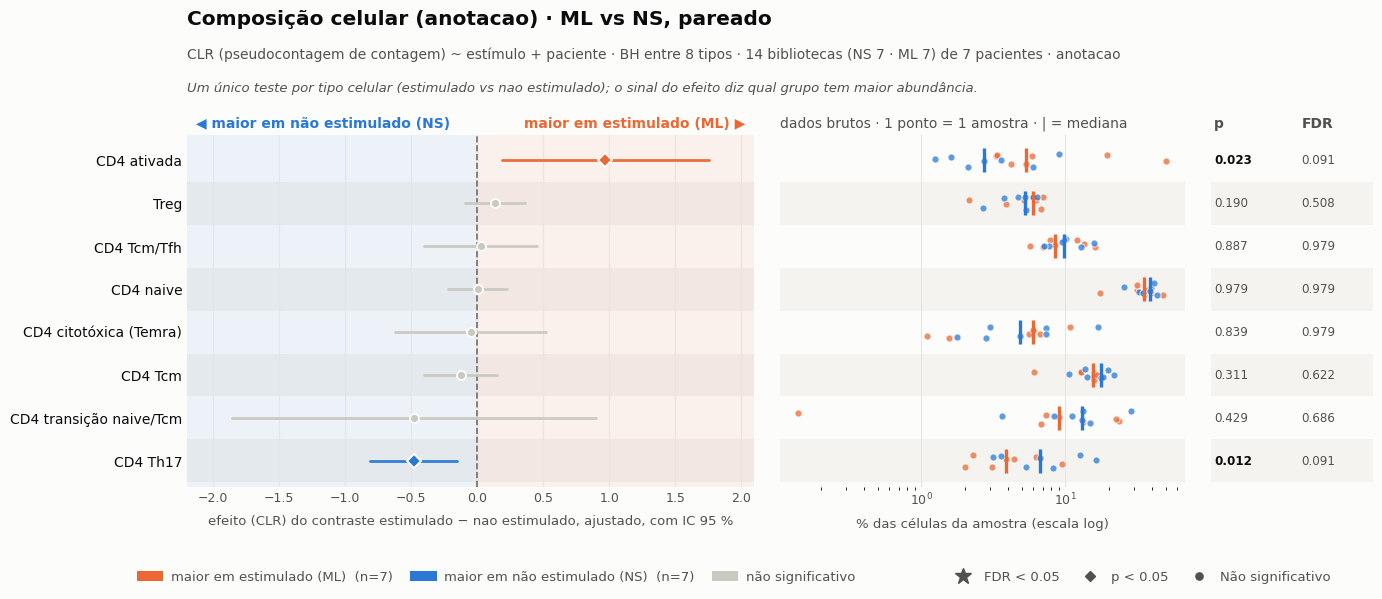

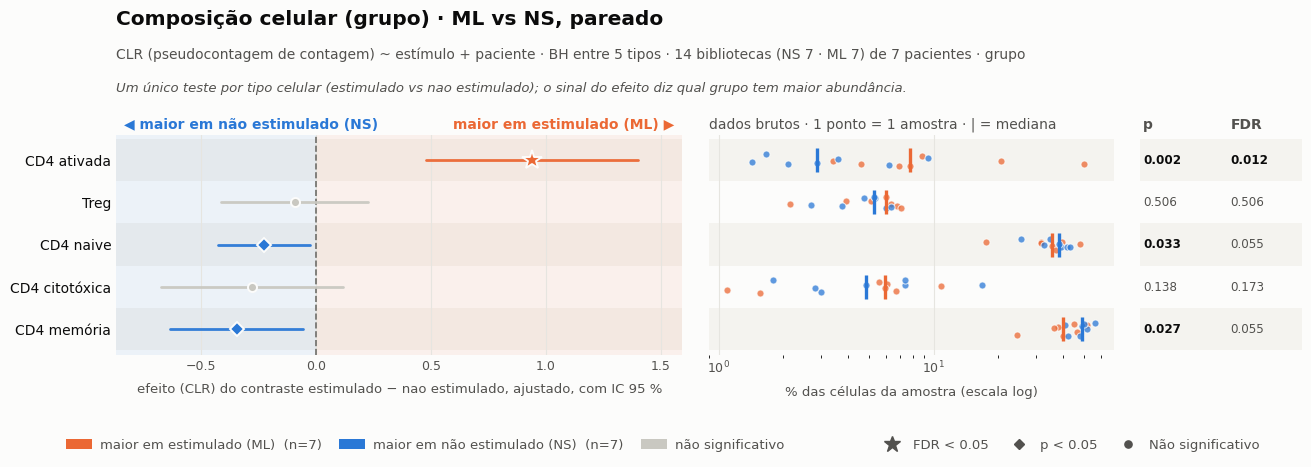

In [8]:
for gran in GRANS:
    res, comp = saidas_c[(gran, "pareado_contagem_prevalencia")]
    n_ns = int((comp["meta"]["estimulo"] == "nao estimulado").sum())
    n_ml = int((comp["meta"]["estimulo"] == "estimulado").sum())
    sub = (f"CLR (pseudocontagem de contagem) ~ estímulo + paciente · BH entre {len(res)} tipos · "
           f"{res.attrs['n_amostras']} bibliotecas (NS {n_ns} · ML {n_ml}) de 7 pacientes · {gran}")
    fig, _ = FR.forest(res, comp, cores_grupo=CORES, rotulos=ROT, subtitulo=sub,
                       titulo=f"Composição celular ({gran}) · ML vs NS, pareado")
    plotting.savefig(fig, NB, f"forest_pareado_{gran}", data=res, data_index=False,
                     description=f"Forest único do contraste ML − NS pareado por paciente ({gran})")
    plt.show()

## 4. Os modelos lado a lado

FDR de cada tipo (`anotacao`) no contraste NS × ML, nos quatro modelos: o E literal das referências
(sem paciente, 1e-6), o E2 pareado com 1e-6, o pareado com a pseudocontagem de contagem, e o de C
completo (com o filtro de prevalência).

In [9]:
lado = pd.DataFrame({nome: saidas_c[(FINA, nome)][0].set_index("cell_population")["FDR"]
                     for nome in ["sem_paciente_1e-6", "pareado_1e-6", "pareado_contagem", "pareado_contagem_prevalencia"]})
efeito = saidas_c[(FINA, "pareado_contagem")][0].set_index("cell_population")["estimate"]
lado.insert(0, "efeito pareado (contagem)", efeito)
lado = lado.sort_values("pareado_contagem")
io.save_table(lado, NB, f"comparacao_modelos_{FINA}", description="FDR do contraste ML − NS nos quatro modelos (anotação)")
display(lado.round(4))

,efeito pareado (contagem),sem_paciente_1e-6,pareado_1e-6,pareado_contagem,pareado_contagem_prevalencia
cell_population,,,,,
CD4 Th17,-0.6199,0.0119,0.0610,0.0604,0.0915
CD4 ativada,0.8329,0.4330,0.3412,0.1622,0.0915
CD4 ativada (Th17),1.3744,0.1257,0.2343,0.1622,NaN
CD4 Tcm,-0.2633,0.0367,0.1707,0.2192,0.6218
CD4 naive,-0.1357,0.1668,0.2343,0.5451,0.9793
CD4 transição naive/Tcm,-0.6165,0.2355,0.2343,0.5451,0.6859
CD4 citotóxica (Temra),-0.1878,0.3247,0.2343,0.6241,0.9793
CD4 Tem GZMK⁺,-0.2686,0.3247,0.3412,0.6241,NaN
CD4 Tcm/Tfh,-0.1123,0.2355,0.2343,0.6592,0.9793


In [10]:
sens = pd.read_csv(TAB / f"sensibilidade_pseudocontagem_{FINA}.csv")
display(sens[sens["contraste"].isin(["C", "D"])].round(4))

,contraste,cell_population,estimate_1e6,p_1e6,FDR_1e6,estimate_contagem,p_contagem,FDR_contagem
0,C,CD4 naive,0.4489,0.5131,0.8870,0.3268,0.3090,0.6125
1,C,CD4 transição naive/Tcm,1.0439,0.3907,0.8870,0.9203,0.2720,0.6125
2,C,CD4 Tcm,-0.2696,0.5463,0.8870,-0.3891,0.0257,0.2063
3,C,CD4 Tcm/Tfh,-0.0696,0.8773,0.9484,-0.1883,0.0561,0.2063
4,C,CD4 Tem GZMK⁺,-2.8924,0.3579,0.8870,0.1228,0.8223,0.9137
5,C,CD4 Th17,-0.7345,0.0644,0.6444,-0.8474,0.0619,0.2063
6,C,CD4 ativada,-0.2845,0.6209,0.8870,-0.3794,0.5798,0.8282
7,C,CD4 ativada (Th17),2.7141,0.4308,0.8870,0.6256,0.3675,0.6125
8,C,CD4 citotóxica (Temra),-0.0641,0.9484,0.9484,-0.1861,0.8039,0.9137
9,C,Treg,0.1078,0.8171,0.9484,-0.0051,0.9877,0.9877


**Consistência entre pacientes.** O modelo pareado dá um efeito médio. Quantos dos 7 pacientes
vão no mesmo sentido? O teste do sinal (binomial exato, bilateral) não depende da pseudocontagem
nem do conjunto de tipos no CLR: com 7 pares, 7 de 7 no mesmo sentido dá p = 0,016 e 6 de 7 dá
p = 0,125.

In [11]:
from scipy.stats import binomtest

_, comp_l2 = saidas_c[(FINA, "pareado_contagem")]
pm = comp_l2["proportion"].join(comp_l2["meta"][["estimulo", "patient"]])
ns = pm[pm["estimulo"] == "nao estimulado"].set_index("patient")[comp_l2["cell_cols"]]
ml = pm[pm["estimulo"] == "estimulado"].set_index("patient")[comp_l2["cell_cols"]].loc[ns.index]
sobe, desce = (ml > ns).sum(), (ml < ns).sum()
cons = pd.DataFrame({
    "pacientes ML > NS": sobe, "pacientes ML < NS": desce,
    "p do sinal": [binomtest(int(max(s, d)), int(s + d)).pvalue if s + d else np.nan for s, d in zip(sobe, desce)],
    "% mediana NS": 100 * ns.median(), "% mediana ML": 100 * ml.median(),
    "FDR pareado 1e-6": saidas_c[(FINA, "pareado_1e-6")][0].set_index("cell_population")["FDR"],
    "FDR pareado C": saidas_c[(FINA, "pareado_contagem_prevalencia")][0].set_index("cell_population")["FDR"],
}).sort_values("p do sinal")
io.save_table(cons, NB, f"consistencia_pacientes_{FINA}",
              description="Por tipo (anotação): pacientes em que ML > NS, teste do sinal e FDR dos modelos pareados")
display(cons.round(3))

,pacientes ML > NS,pacientes ML < NS,p do sinal,% mediana NS,% mediana ML,FDR pareado 1e-6,FDR pareado C
CD4 Th17,0,7,0.016,6.708,3.899,0.061,0.091
CD4 ativada,6,1,0.125,2.723,5.309,0.341,0.091
CD4 ativada (Th17),6,1,0.125,0.151,1.216,0.234,NaN
CD4 Tcm/Tfh,2,5,0.453,9.777,8.437,0.234,0.979
CD4 citotóxica (Temra),2,5,0.453,4.826,5.946,0.234,0.979
Treg,5,2,0.453,5.263,6.013,0.234,0.508
CD4 Tem GZMK⁺,4,3,1.000,0.124,0.140,0.341,NaN
CD4 Tcm,3,4,1.000,17.640,15.493,0.171,0.622
CD4 naive,3,4,1.000,38.530,35.482,0.234,0.979
CD4 transição naive/Tcm,3,4,1.000,13.111,9.047,0.234,0.686


## 5. Interpretação

**O estímulo expande a CD4 ativada, e é isso que muda na composição.** Com a anotação, o sinal é
bem mais claro do que com o atlas L2 (`P15_composicao_atlasL2`), e os modelos concordam: a matriz
biblioteca × anotação tem só 4 zeros (contra 15 no L2), então a pseudocontagem pesa pouco.

**Estímulo (NS × ML), `grupo`.**

* **CD4 ativada sobe em 7 de 7 pacientes** (teste do sinal p = 0,016): +0,97 em CLR (cerca de
  ×2,6) no modelo pareado, p = 0,002, **FDR 0,011**; no modelo de C, FDR 0,012. Sem o paciente
  (E, como no espacial), FDR 0,08: o pareamento é o que dá o poder. O tamanho varia muito: de 9 %
  para 50 % no CTH97 e de 4 % para 21 % no CTH92, contra 6,2 % → 6,9 % no PB21 e 1,7 % → 3,4 % no MB34.
* **CD4 memória cai** (6 de 7; FDR 0,046 pareado, 0,055 em C) e a **naive** cai junto (FDR 0,046),
  mas a naive só desce em 4 de 7: é sobretudo o efeito composicional da expansão da ativada.
* **Treg não muda**: 5,3 % → 6,0 % (mediana), sobe em 5 de 7, FDR 0,52. É o mesmo resultado do P14.

**Estímulo, `anotacao`.**

* **CD4 Th17 cai em 7 de 7** (6,7 % → 3,9 %): FDR 0,012 sem o paciente, 0,061 pareado, 0,06–0,09
  no modelo de C. **CD4 Tcm** cai (FDR 0,037 sem o paciente; 0,17 pareado).
* Ao mesmo tempo, **CD4 ativada (Th17)** sobe em 6 de 7 (0,15 % → 1,2 %) e **CD4 ativada** em 6
  de 7 (2,7 % → 5,3 %). A anotação é por cluster: uma Th17 que se ativa passa para o cluster
  ativado. A queda da Th17 e da Tcm é, ao menos em parte, mudança de estado (de repouso para
  ativada), não perda de células.

**Por que o atlas não via isso.** O atlas de referência foi montado com CD4⁺ de sangue sem
estímulo; as células ativadas são distribuídas entre os tipos de repouso mais parecidos (e parte
vira TregAct, como no P14). A anotação do projeto tem os clusters de ativação.

**PB × controle (C e D).** Nada com FDR < 0,05. O mais perto: CD4 naive maior no PB em ML
(p = 0,052; FDR 0,26).

**Classificação par a par (B, 14 bibliotecas juntas).** No `grupo`, a CD4 naive é maior no PB que
nos controles (p = 0,008; FDR 0,041), mas os contrastes por estímulo (C, D) não confirmam (p = 0,20
e 0,052): o pareamento falso (cada paciente duas vezes) infla esse p. A Treg é maior no MB que nos
controles (p = 0,021; FDR 0,052), como no P14 e no atlas: um paciente, descritivo. Na `anotacao`,
nada passa pelo BH.

**Estímulo dentro dos controles (B).** A CD4 memória (`grupo`, p = 0,015) e a Th17 (`anotacao`,
p = 0,006; FDR 0,063) são menores em ML.

**Agrupamento das bibliotecas (pvclust).** As bibliotecas não se separam por estímulo nem por
grupo clínico. Alguns pares do mesmo paciente ficam juntos (HNP44 e PB21 no `grupo`), e o CTH97_ML
fica sozinho (metade das células ativadas). Com 5 e 10 tipos como variáveis o AU é pouco
confiável (o BP dos ramos com AU ≥ 95 % fica entre 0,11 e 0,58).

**Resumo.** O que muda com o estímulo é a fração de células ativadas, de forma consistente nos 7
pacientes mas com tamanho muito diferente entre eles (os controles CTH97 e CTH92 respondem muito
mais). A Treg não muda. Entre os grupos clínicos, nada sobrevive com inferência válida.

## Problemas encontrados

In [12]:
log.add("INFO", "seção 3", "R e Python dão o mesmo resultado nos modelos em comum",
        evidence=f"max |Δ| estimativa = {conf['max |Δ estimativa|'].max():.1e}; p = {conf['max |Δ p|'].max():.1e}",
        impact="o forest de C e as figuras de A/B vêm do mesmo cálculo",
        recommendation="nenhuma")
log.add("MAJOR", "forests de classificação (B)", "classificação par a par com as 14 bibliotecas juntas",
        evidence="cada paciente entra duas vezes (NS e ML); MB e NP são 1 paciente cada",
        impact="IC e p dos contrastes de classificação são otimistas; MB e NP não generalizam",
        recommendation="ler como descritivo; para inferência, C/D (PB × controle dentro de cada estímulo)")
df_issues = log.save()
issues.show(df_issues)

severity,location,problem,evidence,impact,recommendation
MAJOR,forests de classificação (B),classificação par a par com as 14 bibliotecas juntas,cada paciente entra duas vezes (NS e ML); MB e NP são 1 paciente cada,IC e p dos contrastes de classificação são otimistas; MB e NP não generalizam,"ler como descritivo; para inferência, C/D (PB × controle dentro de cada estímulo)"
INFO,seção 3,R e Python dão o mesmo resultado nos modelos em comum,max |Δ| estimativa = 4.2e-15; p = 2.1e-15,o forest de C e as figuras de A/B vêm do mesmo cálculo,nenhuma
